# Irish Property Price Register — SQL Exploration

Before touching scikit-learn, the first pass over any new dataset should
be: what's actually in here, and does it look right? SQL is a genuinely
good tool for this stage — "average price per county" or "how many sales
per year" are GROUP BY queries, not modelling questions, and SQLite will
answer them over 800k rows in a fraction of a second.

This notebook runs every query in `../sql/queries.sql` against
`../data/processed/housing.db` and renders the results as tables and
charts. The `.sql` file itself is meant to be readable on its own (e.g. if
you just want to copy a query into the `sqlite3` CLI) — this notebook adds
the "look at it" layer on top.

In [1]:
import sqlite3
import re
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid")
BLUE = "#2a78d6"

DB_PATH = "../data/processed/housing.db"
SQL_PATH = "../sql/queries.sql"

conn = sqlite3.connect(DB_PATH)

# queries.sql is a sequence of ';'-terminated statements, each preceded by
# a numbered '-- N. ...' comment. Splitting on ';' and matching that
# comment lets us run "query 3" by number instead of copy-pasting SQL
# between the .sql file and this notebook -- one source of truth for the
# actual query text.
sql_text = Path(SQL_PATH).read_text(encoding="utf-8")
raw_statements = [s.strip() for s in sql_text.split(";") if s.strip()]

def run_query(n):
    for stmt in raw_statements:
        if re.search(rf"--\s*{n}\.", stmt):
            return pd.read_sql_query(stmt, conn)
    raise ValueError(f"No query numbered {n} found in {SQL_PATH}")

## 1. Shape of the dataset

In [2]:
run_query(1)

,total_sales,earliest_sale,latest_sale
0,797774,2010-01-01,2026-07-24


## 2. National average price by year

The clearest single chart in this notebook: what happened to Irish
property prices since the post-2008-crash trough in the early 2010s.

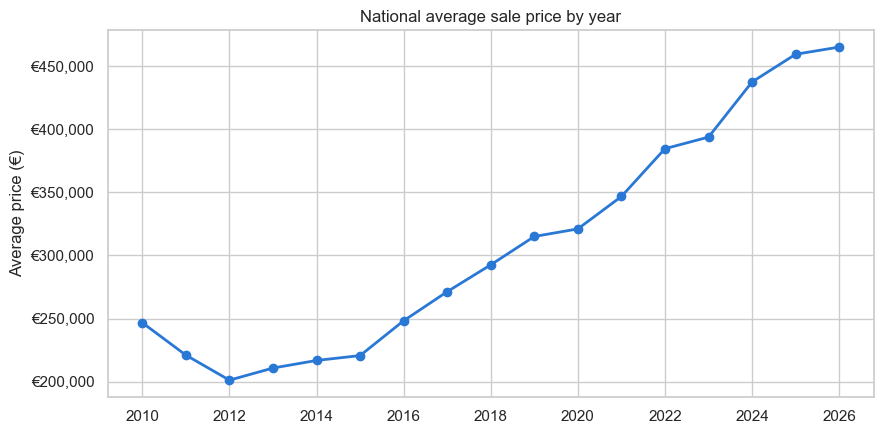

,year,n_sales,avg_price
0,2010,19902,246763.0
1,2011,17350,221094.0
2,2012,23672,201307.0
3,2013,28494,210891.0
4,2014,42555,216903.0
5,2015,47494,220755.0
6,2016,48005,248327.0
7,2017,52344,271320.0
8,2018,54144,292581.0
9,2019,55282,315013.0


In [3]:
yearly = run_query(2)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(yearly["year"], yearly["avg_price"], color=BLUE, marker="o", linewidth=2)
ax.set_title("National average sale price by year")
ax.set_xlabel("")
ax.set_ylabel("Average price (€)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"€{x:,.0f}"))
plt.tight_layout()
plt.show()
yearly

## 3. Average price by county

This is the main justification for putting `county` in the model at all
-- look at the size of the gap between the top and bottom of this chart.

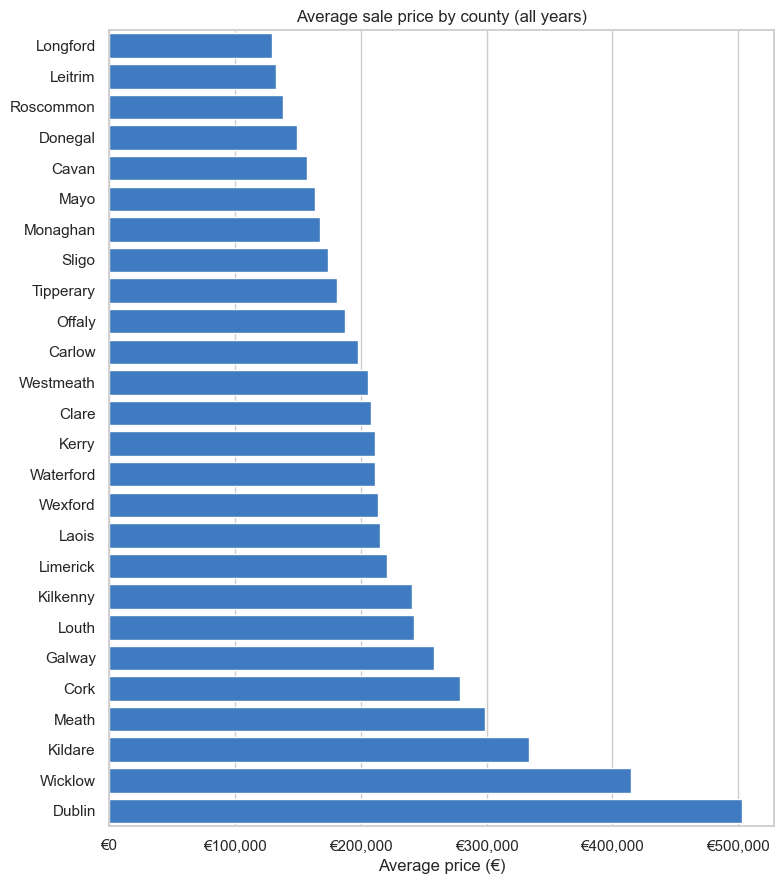

In [4]:
by_county = run_query(3).sort_values("avg_price", ascending=True)

fig, ax = plt.subplots(figsize=(8, 9))
sns.barplot(data=by_county, x="avg_price", y="county", color=BLUE, ax=ax)
ax.set_title("Average sale price by county (all years)")
ax.set_xlabel("Average price (€)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"€{x:,.0f}"))
plt.tight_layout()
plt.show()

## 4. New vs. Second-Hand

In [5]:
run_query(4)

,property_type,n_sales,avg_price
0,New,134398,417867.0
1,Second-Hand,622728,303527.0


## 5. Dublin's own trend over time

Dublin is roughly a third of all national sales, so it's worth checking
whether its trend looks like the national one (query 2) or genuinely
different.

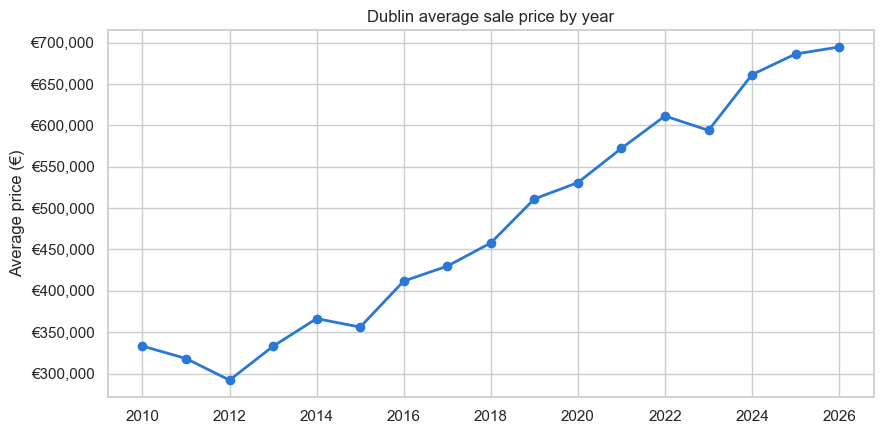

In [6]:
dublin = run_query(5)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(dublin["year"], dublin["avg_price"], color=BLUE, marker="o", linewidth=2)
ax.set_title("Dublin average sale price by year")
ax.set_xlabel("")
ax.set_ylabel("Average price (€)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"€{x:,.0f}"))
plt.tight_layout()
plt.show()

## 6. Which counties grew the fastest, 2011 -> 2025?

This is exactly the kind of pattern a plain linear model struggles with
unless you explicitly add a county × year interaction term: growth rates
aren't uniform across counties, so "one national trend line" undersells
some counties and oversells others.

In [7]:
growth = run_query(6)
growth

,county,avg_price_2011,avg_price_2025,pct_change
0,Westmeath,140287.0,367248.0,161.8
1,Laois,129900.0,321808.0,147.7
2,Louth,159764.0,380545.0,138.2
3,Wexford,145332.0,323999.0,122.9
4,Dublin,318171.0,686118.0,115.6
5,Offaly,136483.0,291546.0,113.6
6,Waterford,152378.0,324440.0,112.9
7,Tipperary,144806.0,307195.0,112.1
8,Kerry,172128.0,363534.0,111.2
9,Carlow,143096.0,300041.0,109.7


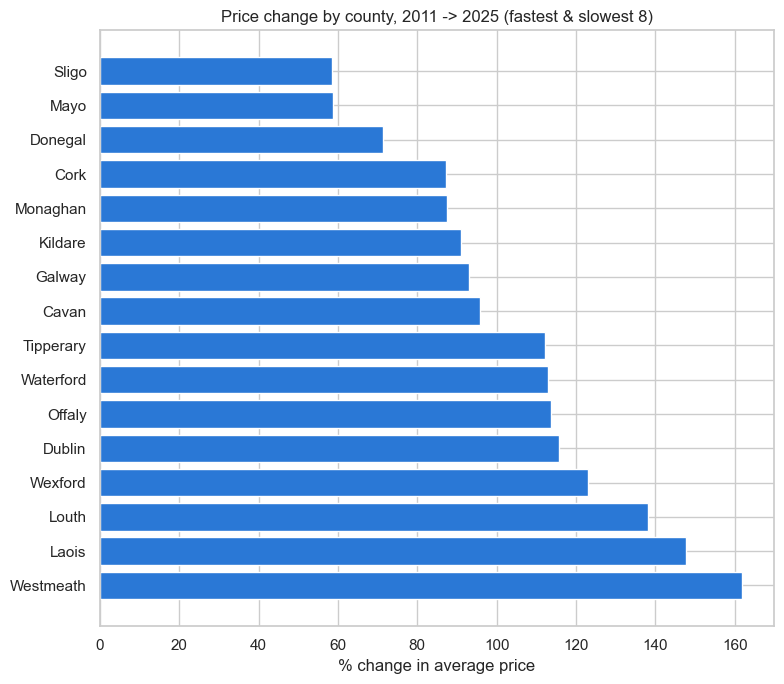

In [8]:
top_bottom = pd.concat([growth.head(8), growth.tail(8)])

fig, ax = plt.subplots(figsize=(8, 7))
colors = [BLUE if v >= 0 else "#e34948" for v in top_bottom["pct_change"]]
ax.barh(top_bottom["county"], top_bottom["pct_change"], color=colors)
ax.set_title("Price change by county, 2011 -> 2025 (fastest & slowest 8)")
ax.set_xlabel("% change in average price")
plt.tight_layout()
plt.show()

## 7. How much of the register is "not full market price"?

Family transfers and similar non-arm's-length sales are a real part of the
register but not representative of what a buyer pays on the open market
-- this is why they get excluded before any modelling.

In [9]:
run_query(7)

,not_full_market_price,n_sales,pct_of_all_sales,avg_price
0,0,757126,94.9,323824.0
1,1,40648,5.1,229256.0


## 8. Highest-priced sales on record (sanity check for outliers)

In [10]:
run_query(8)

,sale_date,address,county,price,property_type
0,2024-10-17,"24 Tinakilly Grove, Tinakilly Park, Rathnew",Wicklow,3.876652e+08,New
1,2024-12-23,"Cooper Square, Seven Mills, Clonburris",Dublin,2.219427e+08,New
2,2026-03-31,"BLOCK A B AND C, NEWMARKET YARDS",Dublin,1.893925e+08,Second-Hand
3,2020-07-17,"Apartments 1 - 186 Cheevers Court, Apartments ...",Dublin,1.823789e+08,New
4,2021-04-15,"8th Lock, Ratoath Road, Pelletstown",Dublin,1.701428e+08,New
5,2025-09-30,"Blocks L J I K F, H1 & H2 Southwest Gate,...",Dublin,1.693250e+08,New
6,2024-12-19,"FLAT C19 BLOCK C, THE POINT CAMPUS, MAIN STREE...",Dublin,1.423370e+08,Second-Hand
7,2019-12-23,"Blocks A and C, The Point Campus",Dublin,1.422566e+08,New
8,2022-12-07,"Apartment Development, at Castleview, Carriglea",Dublin,1.358598e+08,New
9,2019-07-19,"266 Apts & 18 Commercial Units, Heuston South ...",Dublin,1.295000e+08,Second-Hand


## 9. Lowest-priced "full market price" sales

In [11]:
low = run_query(9)
low

,sale_date,address,county,price,property_type
0,2019-03-11,"COULAGHARD, EYERIES, BEARA",Cork,5030.53,Second-Hand
1,2014-07-18,"CLOGHAN, GLENCOLMCILLE, DONEGAL",Donegal,5079.00,Second-Hand
2,2018-09-04,"65 ST JOSEPH'S PARK, NENAGH, CO TIPPERARY",Tipperary,5080.00,Second-Hand
3,2015-05-22,"1 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
4,2015-05-22,"10 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
5,2015-05-22,"11 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
6,2015-05-22,"13 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
7,2015-05-22,"14 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
8,2015-05-22,"15 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New
9,2015-05-22,"16 Greenfields, Lanesboro Road, Roscommon",Roscommon,5179.00,New


Query 9 is worth sitting with for a second: these are sales *not* flagged
as `not_full_market_price`, yet priced at a few hundred or a few thousand
euro -- clearly not genuine open-market transactions either (a shed, a
sliver of land, a data entry error). The flag catches *most* non-market
sales, but not all of them. That's a real limitation of trusting a single
boolean column, and it's called out again in the modelling notebook and
the README rather than silently ignored.

## 10. How complete is the floor-area field?

In [12]:
missing_size = run_query(10)
missing_size

,pct_missing_size
0,0.0


This number is the reason the ML model in `02_modeling.ipynb` doesn't use
property size as a feature at all, even though floor area is probably the
single strongest real predictor of price. It's simply missing for the
overwhelming majority of rows -- the register only requires it to be
declared for some new-build/VAT-exclusive sales.

## Takeaways going into modelling

- `county` clearly matters a lot (query 3) and its effect isn't stable
  over time (query 6) -- a good candidate for letting a model capture
  county-by-year interactions rather than assuming one flat "yearly
  trend" applies everywhere.
- `property_type` (New vs. Second-Hand) shows a real, consistent price gap
  (query 4).
- `not_full_market_price = 1` sales must be excluded before modelling
  (query 7), and a handful of oddly-low "full market price" sales (query
  9) will still act as noisy outliers even after that filter.
- Floor area, bedroom count, and exact location within a county are all
  unavailable — the model can only ever be as good as county + year +
  property type allow it to be. That ceiling is discussed honestly in the
  README and the modelling notebook, not glossed over.